In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import ttest_ind


df2020 = pd.read_csv('2020.csv')
df2021 = pd.read_csv('2021.csv')
df2022 = pd.read_csv('2022.csv')
df2023 = pd.read_csv('2023.csv')
df2024 = pd.read_csv('2024.csv')
df2025 = pd.read_csv('2025.csv')

df2020['Year'] = 2020
df2021['Year'] = 2021
df2022['Year'] = 2022
df2023['Year'] = 2023
df2024['Year'] = 2024
df2025['Year'] = 2025

df = pd.concat([df2020, df2021, df2022, df2023, df2024, df2025], ignore_index=True)

# dependeant (Y) will be W-L%
# independent (X) BA, OPS, and ERA

df.columns

df = df[['Tm','Year','W-L%','BA','OPS','ERA']]
df = df.rename(columns={'Tm': 'Team','W-L%': 'WinPct','BA': 'BattingAvg'})

In [2]:
summary_table = df[['WinPct', 'BattingAvg', 'OPS', 'ERA']].agg(['mean', 'median', 'std', 'min', 'max'])
summary_table

,WinPct,BattingAvg,OPS,ERA
mean,0.499958,0.244536,0.722646,4.205000
median,0.500000,0.244000,0.718500,4.075000
std,0.080361,0.011637,0.038266,0.566376
min,0.253000,0.212000,0.618000,2.800000
max,0.717000,0.276000,0.845000,5.970000


const        -0.161001
BattingAvg    2.702907
dtype: float64


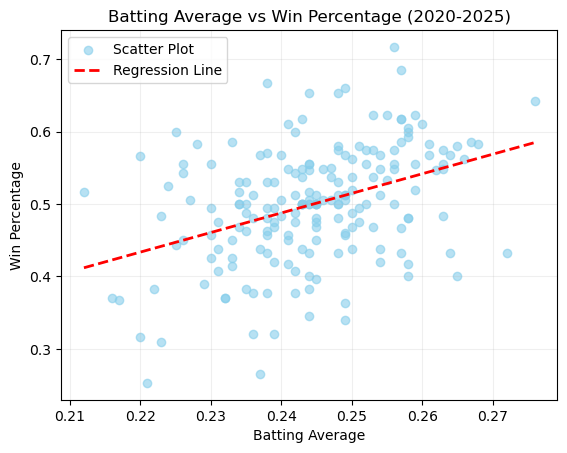

In [3]:

# regression
X = df[['BattingAvg']]
X = sm.add_constant(X)
y = df['WinPct']

ba_model = sm.OLS(y, X).fit()

print(ba_model.params)

paramdf = ba_model.params.reset_index()

# scatter
plt.scatter(df['BattingAvg'], df['WinPct'], label='Scatter Plot', color = 'skyblue', alpha = 0.6)

# x values
x = np.linspace(df['BattingAvg'].min(), df['BattingAvg'].max(), 100)

# y values
y_line = ba_model.params['const'] + ba_model.params['BattingAvg'] * x

# regression line
plt.plot(x, y_line, color='red', linewidth=2, label='Regression Line', linestyle = '--')

plt.xlabel('Batting Average')
plt.ylabel('Win Percentage')
plt.title('Batting Average vs Win Percentage (2020-2025)', fontsize=12)
plt.legend()
plt.grid(alpha=0.2)
plt.savefig("BA vs Win %.png")

plt.show()

const   -0.453296
OPS      1.319117
dtype: float64


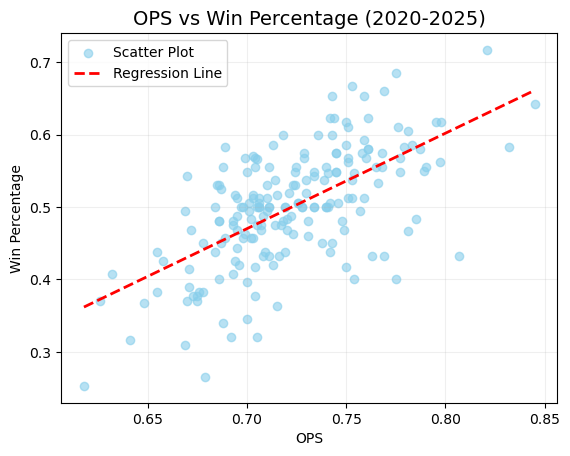

In [4]:

# regression
X = df[['OPS']]
X = sm.add_constant(X)
y = df['WinPct']

ops_model = sm.OLS(y, X).fit()

print(ops_model.params)

paramdf = ops_model.params.reset_index()

# scatter
plt.scatter(df['OPS'], df['WinPct'], label='Scatter Plot', color = 'skyblue', alpha = 0.6)

# x values
x = np.linspace(df['OPS'].min(), df['OPS'].max(), 100)

# y values
y_line = ops_model.params['const'] + ops_model.params['OPS'] * x

# regression line
plt.plot(x, y_line, color='red', linewidth = 2, label='Regression Line', linestyle = '--')

plt.xlabel('OPS')
plt.ylabel('Win Percentage')
plt.title('OPS vs Win Percentage (2020-2025)', fontsize=14)
plt.legend()
plt.grid(alpha=0.2)

plt.savefig("OPS vs Win %.png")

plt.show()

const    0.967576
ERA     -0.111205
dtype: float64


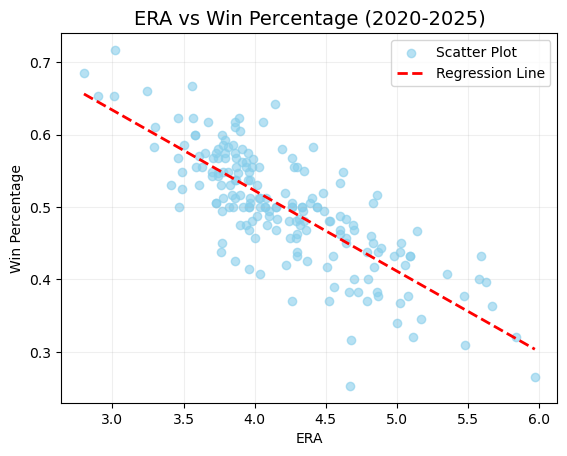

In [5]:

# regression
X = df[['ERA']]
X = sm.add_constant(X)
y = df['WinPct']

era_model = sm.OLS(y, X).fit()

print(era_model.params)

paramdf = era_model.params.reset_index()

# scatter
plt.scatter(df['ERA'], df['WinPct'], label='Scatter Plot', color = 'skyblue', alpha = 0.6)

# x values
x = np.linspace(df['ERA'].min(), df['ERA'].max(), 100)

# y values
y_line = era_model.params['const'] + era_model.params['ERA'] * x

# regression line
plt.plot(x, y_line, color='red', linewidth = 2, label='Regression Line', linestyle = '--')

plt.xlabel('ERA')
plt.ylabel('Win Percentage')
plt.title('ERA vs Win Percentage (2020-2025)', fontsize=14)
plt.legend()
plt.grid(alpha=0.2)

plt.savefig("ERA vs Win %.png")

plt.show()

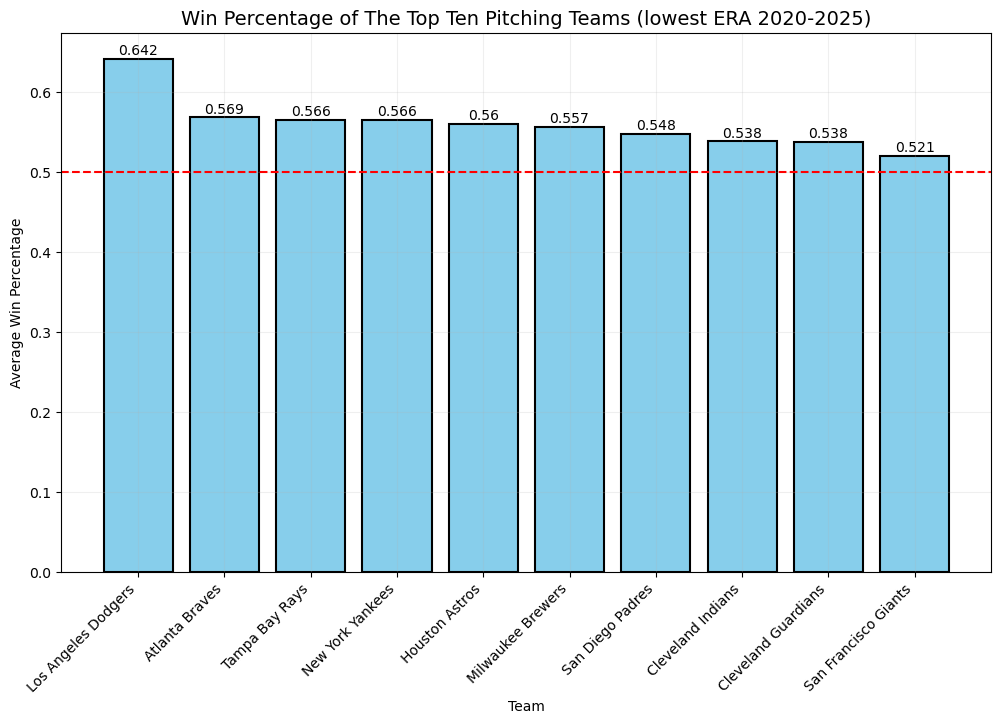

In [10]:
team_avg = df.groupby('Team')[['ERA','WinPct']].mean().reset_index()
team_avg_sorted = team_avg.sort_values('ERA')

top_ten = team_avg_sorted.head(10)
top_ten = top_ten.sort_values('WinPct', ascending=False)

plt.figure(figsize=(12,7))

plt.bar(top_ten['Team'], top_ten['WinPct'], color = 'skyblue', edgecolor = 'black', linewidth=1.5)

plt.xticks(rotation=45, ha='right')
plt.xlabel('Team')
plt.ylabel('Average Win Percentage')
plt.title('Win Percentage of The Top Ten Pitching Teams (lowest ERA 2020-2025)', fontsize=14)

plt.axhline(y=0.50, linestyle='--', color = 'red')
for row_index in range(len(top_ten)):
    win_pct = top_ten['WinPct'].iloc[row_index]
    plt.text(row_index, win_pct+0.005, round(win_pct,3), ha='center')

plt.grid(alpha=0.2)

plt.savefig("Top Ten Pitcher Win %.png")

plt.show()

In [11]:
df['ERA_Level'] = 'High ERA'
df.loc[df['ERA'] <= df['ERA'].median(), 'ERA_Level'] = 'Low ERA'

low_era = df[df['ERA_Level'] == 'Low ERA']['WinPct']
high_era = df[df['ERA_Level'] == 'High ERA']['WinPct']

t_stat, p_value = ttest_ind(low_era, high_era)

print('t-stat: ', t_stat)
print('p-value: ', p_value)

# p-value is essentially zero meaning we reject the null hypothesis
# strong evidence that low ERA teams have a higher win %

t-stat:  10.677252914003043
p-value:  3.796426640788287e-21


In [12]:
print(ba_model.params)
print(ops_model.params)
print(era_model.params)

const        -0.161001
BattingAvg    2.702907
dtype: float64
const   -0.453296
OPS      1.319117
dtype: float64
const    0.967576
ERA     -0.111205
dtype: float64
